In [40]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import skimage as ski
import scipy as sp
import imageio.v3 as iio


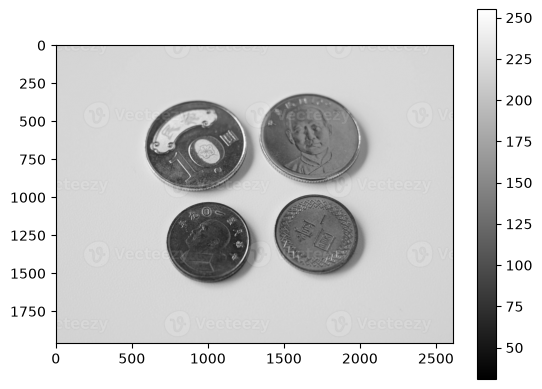

cercle détecté : centre=(1770, 513), taille=290
cercle détecté : centre=(981, 682), taille=224
cercle détecté : centre=(752, 695), taille=310
cercle détecté : centre=(1878, 622), taille=270
cercle détecté : centre=(1792, 578), taille=204
cercle détecté : centre=(1805, 418), taille=154
cercle détecté : centre=(1848, 479), taille=200
cercle détecté : centre=(752, 548), taille=230
cercle détecté : centre=(1142, 708), taille=194
cercle détecté : centre=(752, 795), taille=188
cercle détecté : centre=(708, 622), taille=148
cercle détecté : centre=(1051, 669), taille=260
cercle détecté : centre=(1168, 1328), taille=190
13 cercles détectés


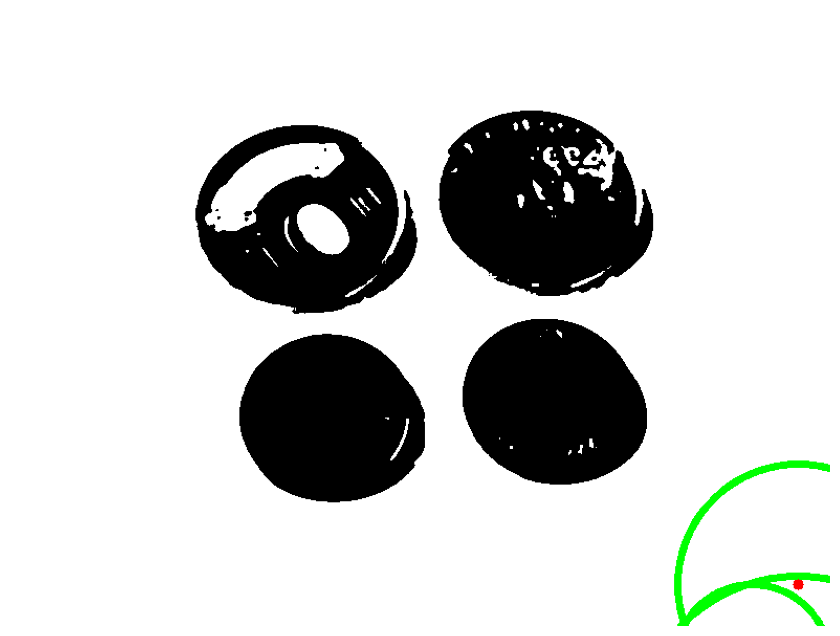

In [29]:
chemin = './data/1-yuan-and-10-yuan-taiwan-coin-close-up-isolated-on-a-white-background-photo.jpg'

taille = plt.imread(chemin)
a_gris = cv2.cvtColor(taille, cv2.COLOR_RGB2GRAY)
plt.imshow(a_gris, cmap='gray')
plt.colorbar()
plt.show()

piece = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) # on force l'image a rester en niveau de gris (car c'est plus simple pour detecter les cercles)
#piece = piece[:270, 80:420] # on recadre jsp si c'est vrm utile
echelle = 0.3
piece_reduite = cv2.resize(piece, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA) # pour reduire la quelité pour que ça aille plus vite
piece_floue = cv2.medianBlur(piece_reduite, 5) # pour ne pas etre perturbé par certain détail (c'est juste pour la detection des cercles)
seuil, img_binaire = cv2.threshold(piece_floue, 150, 255, cv2.THRESH_BINARY)
image_resultat = cv2.cvtColor(img_binaire, cv2.COLOR_GRAY2RGB) # permet a la fin de pouvoir rajouter des couleurs sur l'image (car plus tot j'ai forcer l'image a rester en niveau de gris)

cercles = cv2.HoughCircles(
    img_binaire, # l'image sur la quel on cherche les cercles
    cv2.HOUGH_GRADIENT, # la methode
    dp=1.3, # a quel point ça dois etre un cercle parfait (1 c'est parfait, 1.2 ça peut être légeremnt oval)
    minDist=20, # la distance minimale entre 2 cercle, pour eviter de detecter 2 fois la mme piece
    param1=50, # plus c'est haut plus le contours doit etre net pour etre detecte
    param2=20, # le taux de fiabilité (plus c'est haut plus il a tendance a detecter des cercle)
    minRadius=20, # les limite de tailles des rayons des cercle
    maxRadius=50,
)

if piece is None:
    raise FileNotFoundError(f'Image introuvable : {chemin}')

if cercles is None:
    print('Aucun cercle détecté. Essaie de diminuer param2 ou ajuste minRadius/maxRadius.')
else:
    cercles = np.round(cercles[0] / echelle).astype(int)
    for x, y, rayon in cercles:
        cv2.circle(image_resultat, (x, y), rayon, (0, 255, 0), 5)
        cv2.circle(image_resultat, (x, y), 5, (255, 0, 0), -1)
        print(f'cercle détecté : centre=({x}, {y}), taille={rayon*2}')
    print(f'{len(cercles)} cercles détectés')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()

In [ ]:
import imageio.v3 as iio
import matplotlib.pyplot as plt
import skimage as ski


coins = "./data/43fef775db14373494f2246ff3754a16_t.jpg"
edges = ski.feature.canny(coins / 255.)
fill_coins = sp.ndimage.binary_fill_holes(edges)

TypeError: unsupported operand type(s) for /: 'str' and 'float'

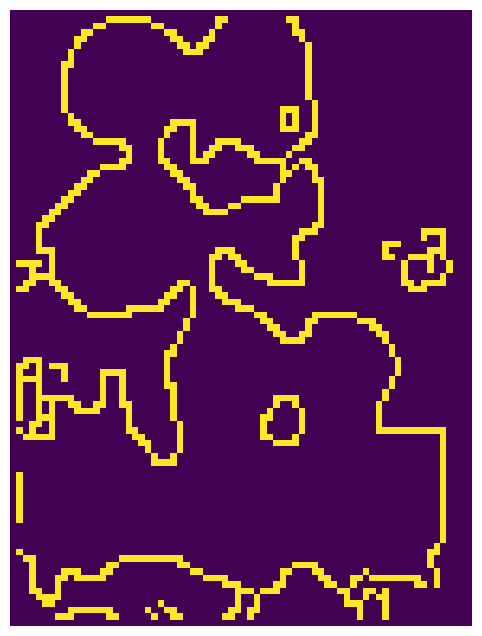

In [42]:
image = './data/images.jpg'
img = cv2.imread(image, cv2.IMREAD_GRAYSCALE)
echelle = 0.15
piece_reduite = cv2.resize(img, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA)
piece_floue = cv2.medianBlur(piece_reduite, 5)
seuil, img_binaire = cv2.threshold(piece_floue, 127, 255, cv2.THRESH_BINARY)
edges = ski.feature.canny(img_binaire / 255.)
fill_coins = sp.ndimage.binary_fill_holes(edges)

plt.figure(figsize=(14, 8))
plt.imshow(edges)
plt.axis('off')
plt.show()